# **Previsão de Churn (Abandono) em Telecom (Modelo Mitra)**

# 1. Importando bibliotecas

In [1]:
# Célula 3: Instalação do AutoGluon e Optuna (Modo Robusto)
# O comando --no-cache-dir previne erros de Hash Mismatch (arquivo corrompido)
# O comando --upgrade pip garante que o instalador esteja atualizado

!pip install --upgrade pip --quiet
!pip install autogluon optuna ipykernel --upgrade --no-cache-dir --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 31.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires ipykernel==6.17.1, but you have ipykernel 7.1.0 which is incompatible.
torchaudio 2.9.0+cu126 requires torch==2.9.0, but you have torch 2.7.1 which is incompatible.
notebook 6.5.7 requires jupyter-client<8,>=5.3.4, but you have jupyter-client 8.7.0 which is incompatible.


In [2]:
# Importar bibliotecas
import pandas as pd
import numpy as np
import torch.nn as nn
import optuna
from sklearn.metrics import accuracy_score, log_loss, classification_report, mean_squared_error
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import precision_recall_curve
from scipy.stats import ks_2samp
from sklearn.exceptions import ConvergenceWarning
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.utils import shuffle
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge, Circle, Rectangle
from matplotlib_venn import venn2
import seaborn as sns
from copy import deepcopy
import warnings

# Remove warnings:
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# 2. Importando banco de dados


In [3]:
# Célula 6: Carregar Base de Dados
import io
import pandas as pd
from google.colab import files

try:
    # Tenta ler o arquivo se ele já estiver no ambiente (ex: de uma sessão anterior)
    data = pd.read_csv("customer_churn_telecom_services.csv")
    print("✅ Arquivo encontrado no disco! Carregando...")
except FileNotFoundError:
    # Se não encontrar, pede o upload
    print("Arquivo não encontrado. Por favor, faça o upload do 'customer_churn_telecom_services.csv':")
    uploaded = files.upload()

    # Pega o nome do arquivo enviado (para garantir que lê o certo)
    file_name = next(iter(uploaded))
    data = pd.read_csv(io.BytesIO(uploaded[file_name]))

print(f"\nDataset carregado com sucesso! Dimensões: {data.shape}")
data.head()

Arquivo não encontrado. Por favor, faça o upload do 'customer_churn_telecom_services.csv':


Saving customer_churn_telecom_services.csv to customer_churn_telecom_services.csv

Dataset carregado com sucesso! Dimensões: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# 3. Dividindo dados

In [4]:
from sklearn.utils import shuffle
import pandas as pd

def separa_classe(df_class, seed=42):
    df_class = shuffle(df_class, random_state=seed)
    n = len(df_class)
    train = df_class.iloc[:int(0.5*n)]
    val   = df_class.iloc[int(0.5*n):int(0.75*n)]
    test  = df_class.iloc[int(0.75*n):]
    return train, val, test

def balanceamento(df_maior, df_menor, seed=42):
    df_menor_bal = df_menor.sample(n=len(df_maior), replace=True, random_state=seed)
    return df_menor_bal

def junta_e_mistura(df_x, df_y, seed=42):
    return shuffle(pd.concat([df_x, df_y]), random_state=seed)


In [5]:
# =========================
# Split por classe + balance (só treino/val) + concat
# =========================
SEED = 42

# Separar classes
data_cl0 = data[data["Churn"] == "No"]
data_cl1 = data[data["Churn"] == "Yes"]

# Split 50/25/25 em cada classe
data_cl0_train, data_cl0_val, data_cl0_test = separa_classe(data_cl0, seed=SEED)
data_cl1_train, data_cl1_val, data_cl1_test = separa_classe(data_cl1, seed=SEED)

# Balancear APENAS treino e validação da classe minoritária (classe 1 = Yes)
data_cl1_train = balanceamento(data_cl0_train, data_cl1_train, seed=SEED)
data_cl1_val   = balanceamento(data_cl0_val,   data_cl1_val,   seed=SEED)

# Concatenar e embaralhar treino e validação
data_train = junta_e_mistura(data_cl0_train, data_cl1_train, seed=SEED)
data_val   = junta_e_mistura(data_cl0_val,   data_cl1_val,   seed=SEED)

# Teste: concatenar (embaralhar é opcional; você disse que não precisa)
data_test  = pd.concat([data_cl0_test, data_cl1_test], axis=0)

print("Tamanhos finais:")
print("Treino:", data_train.shape)
print("Validação:", data_val.shape)
print("Teste:", data_test.shape)


Tamanhos finais:
Treino: (5174, 20)
Validação: (2586, 20)
Teste: (1762, 20)


In [6]:
print("Tamanhos finais:")
print("Treino:", data_train.shape)
print("Validação:", data_val.shape)
print("Teste:", data_test.shape)

Tamanhos finais:
Treino: (5174, 20)
Validação: (2586, 20)
Teste: (1762, 20)


# 4. Tratamento de dados

In [7]:
# ===============================
# Funções de pré-processamento
# ===============================

def fix_inconsistencies(df):
    df = df.copy()

    # 1. Resolver TotalCharges (string -> numeric)
    if "TotalCharges" in df.columns:
        df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
        df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

    # 2. SeniorCitizen -> Yes/No
    if "SeniorCitizen" in df.columns:
        df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"}).astype("object")

    return df


def treat_missing(df):
    df = df.copy()

    df = df.replace("", np.nan)

    num_cols = df.select_dtypes(include=['number']).columns
    cat_cols = df.select_dtypes(include=['object', 'category']).columns

    df[num_cols] = df[num_cols].fillna(df[num_cols].median())
    df[cat_cols] = df[cat_cols].fillna("Missing")

    return df

In [8]:
# 0. Copia banco de dados
tratando_train = data_train.copy()
tratando_val = data_val.copy()
tratando_test = data_test.copy()

In [9]:
# 1. Fix Inconsistências
tratando_train = fix_inconsistencies(tratando_train)
tratando_val = fix_inconsistencies(tratando_val)
tratando_test = fix_inconsistencies(tratando_test)

In [10]:
# 2. Missing
tratando_train = treat_missing(tratando_train)
tratando_val = treat_missing(tratando_val)
tratando_test = treat_missing(tratando_test)

In [11]:
# 3. Transformações
tratando_train["Churn"] = tratando_train["Churn"].map({"Yes": 1, "No": 0})
tratando_val["Churn"] = tratando_val["Churn"].map({"Yes": 1, "No": 0})
tratando_test["Churn"] = tratando_test["Churn"].map({"Yes": 1, "No": 0})

In [12]:
# 4. Separa valores target do resto do datasets:
target = "Churn"

# - Separa valores target de treino, validação e teste:
y_train = tratando_train[target]
y_val   = tratando_val[target]
y_test  = tratando_test[target]

# - Remover os valores target dos datasets para passar ao preprocessor:
tratando_train = tratando_train.drop(columns=[target])
tratando_val = tratando_val.drop(columns=[target])
tratando_test = tratando_test.drop(columns=[target])

In [19]:
# =========================
# 5. Montar DataFrames para AutoGluon (sem OHE/Scaler manual)
# + corrigir índices duplicados gerados pelo oversampling
# =========================

train_df = tratando_train.copy()
train_df["target"] = y_train.values
train_df = train_df.reset_index(drop=True)  # <- FIX

val_df = tratando_val.copy()
val_df["target"] = y_val.values
val_df = val_df.reset_index(drop=True)      # <- FIX (principal)

test_df = tratando_test.copy()
test_df["target"] = y_test.values
test_df = test_df.reset_index(drop=True)    # <- FIX (segurança)

print("✅ DataFrames para AutoGluon prontos (índices únicos):")
print("train_df:", train_df.shape, "| val_df:", val_df.shape, "| test_df:", test_df.shape)
print("Duplicados train_df?", train_df.index.duplicated().any())
print("Duplicados val_df?", val_df.index.duplicated().any())
print("Duplicados test_df?", test_df.index.duplicated().any())


✅ DataFrames para AutoGluon prontos (índices únicos):
train_df: (5174, 20) | val_df: (2586, 20) | test_df: (1762, 20)
Duplicados train_df? False
Duplicados val_df? False
Duplicados test_df? False


# 5. Configuração para Optuna e AutoGluon

In [14]:
# Configurações do Espaço de Busca
# AutoGluon é muito eficiente, então vamos otimizar os parâmetros de um modelo interno (GBM - LightGBM)
# para manter a lógica de otimização pedida.
gbm_options = {
    'num_boost_round': 100,  # Fixo para rapidez no loop
    'learning_rate': optuna.distributions.LogUniformDistribution(1e-4, 1e-1),
    'num_leaves': optuna.distributions.IntUniformDistribution(20, 64)
}

# Caminho temporário para salvar modelos do Optuna
path_root = "ag_optuna_trials"

/tmp/ipython-input-1449066828.py:6: FutureWarning: LogUniformDistribution has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use :class:`~optuna.distributions.FloatDistribution` instead.
  'learning_rate': optuna.distributions.LogUniformDistribution(1e-4, 1e-1),
/tmp/ipython-input-1449066828.py:7: FutureWarning: IntUniformDistribution has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use :class:`~optuna.distributions.IntDistribution` instead.
  'num_leaves': optuna.distributions.IntUniformDistribution(20, 64)


# 6. Treinamento

In [15]:
# ==============================================================================
# IMPORTAÇÃO DE EMERGÊNCIA (AutoGluon + Bibliotecas)
# ==============================================================================
import pandas as pd
import numpy as np
import optuna
import shutil
import os
import warnings

# Importação Crítica do AutoGluon
try:
    from autogluon.tabular import TabularPredictor
    print("✅ AutoGluon (TabularPredictor) importado com sucesso!")
except ImportError:
    print("⚠️ AutoGluon não encontrado. Tentando instalar novamente...")
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "autogluon", "--quiet"])
    from autogluon.tabular import TabularPredictor
    print("✅ AutoGluon instalado e importado!")

# Outros imports necessários para o loop
from sklearn.metrics import log_loss

# Ignorar avisos chatos
warnings.filterwarnings("ignore")

print("Todas as bibliotecas estão carregadas. Pode rodar a Célula 23 agora.")

✅ AutoGluon (TabularPredictor) importado com sucesso!
Todas as bibliotecas estão carregadas. Pode rodar a Célula 23 agora.


In [16]:
# ==============================================================================
# RECUPERAÇÃO DE DADOS (Executa passos 7 a 18 de uma vez)
# ==============================================================================
print("Reconstruindo variáveis de treino e teste...")

# 1. Funções de Apoio
def separa_classe(df_class):
    df_class = shuffle(df_class, random_state=42)
    n = len(df_class)
    train = df_class.iloc[:int(0.5*n)]
    val   = df_class.iloc[int(0.5*n):int(0.75*n)]
    test  = df_class.iloc[int(0.75*n):]
    return train, val, test

def balanceamento(df_maior, df_menor):
    return df_menor.sample(n=len(df_maior), replace=True, random_state=42)

def junta_e_mistura(df_x, df_y):
    return shuffle(pd.concat([df_x, df_y]), random_state=42)

def fix_inconsistencies(df):
    df = df.copy()
    if "TotalCharges" in df.columns:
        df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
        df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
    if "SeniorCitizen" in df.columns:
        df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"}).astype("object")
    return df

def treat_missing(df):
    df = df.copy()
    df = df.replace("", np.nan)
    num_cols = df.select_dtypes(include=['number']).columns
    cat_cols = df.select_dtypes(include=['object', 'category']).columns
    df[num_cols] = df[num_cols].fillna(df[num_cols].median())
    df[cat_cols] = df[cat_cols].fillna("Missing")
    return df

# 2. Divisão e Balanceamento
target = "Churn"
if 'data' not in locals():
    print("❌ Erro: Variável 'data' não existe. Rode a Célula 6 (Upload) primeiro.")
else:
    # Separação
    data_cl0 = data[data["Churn"] == "No"]
    data_cl1 = data[data["Churn"] == "Yes"]

    data_cl0_train, data_cl0_val, data_cl0_test = separa_classe(data_cl0)
    data_cl1_train, data_cl1_val, data_cl1_test = separa_classe(data_cl1)

    # Balanceamento
    data_cl1_train = balanceamento(data_cl0_train, data_cl1_train)
    data_cl1_val = balanceamento(data_cl0_val, data_cl1_val)

    # Junção
    data_train = junta_e_mistura(data_cl0_train, data_cl1_train)
    data_val = junta_e_mistura(data_cl0_val, data_cl1_val)
    data_test = junta_e_mistura(data_cl0_test, data_cl1_test)

    # 3. Pré-processamento
    # Cópia
    tratando_train = data_train.copy()
    tratando_val = data_val.copy()
    tratando_test = data_test.copy()

    # Aplicação das funções
    for df in [tratando_train, tratando_val, tratando_test]:
        df = fix_inconsistencies(df)
        df = treat_missing(df)
        df[target] = df[target].map({"Yes": 1, "No": 0})

    # Atualiza as variáveis após o loop (o loop acima não atualiza a referencia original se não reatribuir)
    tratando_train = fix_inconsistencies(tratando_train)
    tratando_train = treat_missing(tratando_train)
    tratando_train[target] = tratando_train[target].map({"Yes": 1, "No": 0})

    tratando_val = fix_inconsistencies(tratando_val)
    tratando_val = treat_missing(tratando_val)
    tratando_val[target] = tratando_val[target].map({"Yes": 1, "No": 0})

    tratando_test = fix_inconsistencies(tratando_test)
    tratando_test = treat_missing(tratando_test)
    tratando_test[target] = tratando_test[target].map({"Yes": 1, "No": 0})

    # 4. Separação X e y
    y_train = tratando_train[target]
    y_val   = tratando_val[target]
    y_test  = tratando_test[target]

    tratando_train = tratando_train.drop(columns=[target])
    tratando_val = tratando_val.drop(columns=[target])
    tratando_test = tratando_test.drop(columns=[target])

    # 5. Encoding e Normalização
    num_cols = tratando_train.select_dtypes(include=['int64','float64','float32']).columns
    cat_cols = tratando_train.select_dtypes(include=['object','category']).columns

    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
    ])

    preprocessor.fit(tratando_train)

    x_train = preprocessor.transform(tratando_train)
    x_val   = preprocessor.transform(tratando_val)
    x_test  = preprocessor.transform(tratando_test)

    print(f"✅ Variáveis recriadas com sucesso!")
    print(f"x_train shape: {x_train.shape}")

Reconstruindo variáveis de treino e teste...
✅ Variáveis recriadas com sucesso!
x_train shape: (5174, 46)


In [20]:
import shutil
from sklearn.metrics import log_loss
from autogluon.tabular import TabularPredictor

def objective(trial):
    lr = trial.suggest_float("learning_rate", 1e-4, 1e-1, log=True)
    num_leaves = trial.suggest_int("num_leaves", 16, 128)
    min_data_in_leaf = trial.suggest_int("min_data_in_leaf", 10, 200)
    feature_fraction = trial.suggest_float("feature_fraction", 0.6, 1.0)
    bagging_fraction = trial.suggest_float("bagging_fraction", 0.6, 1.0)
    lambda_l2 = trial.suggest_float("lambda_l2", 1e-8, 10.0, log=True)

    hyperparameters = {
        "GBM": {
            "learning_rate": lr,
            "num_leaves": num_leaves,
            "min_data_in_leaf": min_data_in_leaf,
            "feature_fraction": feature_fraction,
            "bagging_fraction": bagging_fraction,
            "lambda_l2": lambda_l2,
            "num_boost_round": 300,
            "verbose": -1
        }
    }

    trial_path = f"{path_root}/trial_{trial.number}"
    predictor = TabularPredictor(label="target", path=trial_path, verbosity=0)

    predictor.fit(
        train_data=train_df,
        tuning_data=val_df,
        hyperparameters=hyperparameters,
        time_limit=None
    )

    y_pred_proba = predictor.predict_proba(val_df.drop(columns=["target"]))[1]
    loss = log_loss(y_val, y_pred_proba)

    shutil.rmtree(trial_path, ignore_errors=True)
    return loss



In [21]:
# Execução do Optuna
# Usamos 10 a 20 trials pois AutoGluon escreve em disco e é mais lento que Scikit-Learn puro
print("Iniciando otimização do AutoGluon...")
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=15)

[I 2025-12-17 13:46:32,948] A new study created in memory with name: no-name-fcfe0a64-2bf9-454b-a2ea-4ef6def9853b


Iniciando otimização do AutoGluon...


[I 2025-12-17 13:46:39,494] Trial 0 finished with value: 0.6755958157289522 and parameters: {'learning_rate': 0.0010740900111259881, 'num_leaves': 125, 'min_data_in_leaf': 191, 'feature_fraction': 0.9873840326455202, 'bagging_fraction': 0.8505744869719027, 'lambda_l2': 0.0092319190441924}. Best is trial 0 with value: 0.6755958157289522.
[I 2025-12-17 13:46:41,311] Trial 1 finished with value: 0.692142217732843 and parameters: {'learning_rate': 0.0007469374730518349, 'num_leaves': 85, 'min_data_in_leaf': 153, 'feature_fraction': 0.9137298395542909, 'bagging_fraction': 0.7199772415539132, 'lambda_l2': 5.245483927507729e-06}. Best is trial 0 with value: 0.6755958157289522.
[I 2025-12-17 13:46:43,213] Trial 2 finished with value: 0.4980030350013844 and parameters: {'learning_rate': 0.02293359343213979, 'num_leaves': 32, 'min_data_in_leaf': 147, 'feature_fraction': 0.7957563277460082, 'bagging_fraction': 0.6676827744594668, 'lambda_l2': 1.2299743418077978e-08}. Best is trial 2 with value: 0

In [22]:
# Resultados
print("Melhores parâmetros encontrados:", study.best_params)
print("Melhor LogLoss:", study.best_value)

Melhores parâmetros encontrados: {'learning_rate': 0.05774214711023688, 'num_leaves': 61, 'min_data_in_leaf': 176, 'feature_fraction': 0.8059756780371117, 'bagging_fraction': 0.9372651263125867, 'lambda_l2': 0.4850833771086356}
Melhor LogLoss: 0.49652558100073385


In [23]:
import os, shutil
from autogluon.tabular import TabularPredictor

best_params = study.best_params

final_path = "Mitra_AutoGluon_Final"
if os.path.exists(final_path):
    shutil.rmtree(final_path)

# Modelo final (GBM com params do Optuna)
final_hyperparameters = {
    "GBM": {
        "learning_rate": best_params["learning_rate"],
        "num_leaves": best_params["num_leaves"],
        "min_data_in_leaf": best_params["min_data_in_leaf"],
        "feature_fraction": best_params["feature_fraction"],
        "bagging_fraction": best_params["bagging_fraction"],
        "lambda_l2": best_params["lambda_l2"],
        "num_boost_round": 800,
        "verbose": -1
    }
}

final_predictor = TabularPredictor(label="target", path=final_path, verbosity=0)


In [24]:
print("Treinando Modelo Final AutoGluon (GBM otimizado)...")

final_predictor.fit(
    train_data=train_df,
    tuning_data=val_df,              # mantém validação separada
    hyperparameters=final_hyperparameters,
    time_limit=None
)

print("✅ Modelo Final Treinado.")


Treinando Modelo Final AutoGluon (GBM otimizado)...
✅ Modelo Final Treinado.


# 7. Analize de desempenho

In [25]:
import numpy as np

print("Gerando previsões...")

X_train = train_df.drop(columns=["target"])
X_val   = val_df.drop(columns=["target"])
X_test  = test_df.drop(columns=["target"])

y_train_pred = final_predictor.predict(X_train)
y_val_pred   = final_predictor.predict(X_val)
y_test_pred  = final_predictor.predict(X_test)

y_train_proba = final_predictor.predict_proba(X_train)[1]
y_val_proba   = final_predictor.predict_proba(X_val)[1]
y_test_proba  = final_predictor.predict_proba(X_test)[1]


Gerando previsões...


In [26]:
# === 2. Relatórios de classificação ===
print("==== CLASSIFICATION REPORT - TREINO ====")
print(classification_report(y_train, y_train_pred))

print("==== CLASSIFICATION REPORT - VALIDAÇÃO ====")
print(classification_report(y_val, y_val_pred))

print("==== CLASSIFICATION REPORT - TESTE ====")
print(classification_report(y_test, y_test_pred))

==== CLASSIFICATION REPORT - TREINO ====
              precision    recall  f1-score   support

           0       0.83      0.79      0.81      2587
           1       0.80      0.84      0.82      2587

    accuracy                           0.81      5174
   macro avg       0.81      0.81      0.81      5174
weighted avg       0.81      0.81      0.81      5174

==== CLASSIFICATION REPORT - VALIDAÇÃO ====
              precision    recall  f1-score   support

           0       0.79      0.74      0.77      1293
           1       0.76      0.81      0.78      1293

    accuracy                           0.77      2586
   macro avg       0.78      0.77      0.77      2586
weighted avg       0.78      0.77      0.77      2586

==== CLASSIFICATION REPORT - TESTE ====
              precision    recall  f1-score   support

           0       0.90      0.75      0.82      1294
           1       0.53      0.76      0.62       468

    accuracy                           0.75      1762
   

In [27]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("== Métricas com threshold padrão do AutoGluon (pred) ==")
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1-Score:", f1_score(y_test, y_test_pred))

# Se o best_threshold existir (da Célula 37), calcula métricas com threshold KS
if "best_threshold" in globals():
    y_test_pred_ks = (np.array(y_test_proba) >= best_threshold).astype(int)
    print("\n== Métricas com threshold do KS ==")
    print("Threshold KS:", best_threshold)
    print("Precision:", precision_score(y_test, y_test_pred_ks))
    print("Recall:", recall_score(y_test, y_test_pred_ks))
    print("F1-Score:", f1_score(y_test, y_test_pred_ks))
else:
    print("\n(best_threshold ainda não foi calculado; rode a Célula 37.)")


== Métricas com threshold padrão do AutoGluon (pred) ==
Precision: 0.526706231454006
Recall: 0.7585470085470085
F1-Score: 0.6217162872154116

(best_threshold ainda não foi calculado; rode a Célula 37.)


In [28]:
# === 4. MSE (Erro Médio Quadrado) ===
print("MSE Treino:", mean_squared_error(y_train, y_train_pred))
print("MSE Validação:", mean_squared_error(y_val, y_val_pred))
print("MSE Teste:", mean_squared_error(y_test, y_test_pred))

MSE Treino: 0.18689601855431
MSE Validação: 0.2254447022428461
MSE Teste: 0.24517593643586832


In [29]:
# === 5. Log Loss ===
print("Log Loss Treino:", log_loss(y_train, y_train_proba))
print("Log Loss Validação:", log_loss(y_val, y_val_proba))
print("Log Loss Teste:", log_loss(y_test, y_test_proba))

Log Loss Treino: 0.418073386517184
Log Loss Validação: 0.49652558100073385
Log Loss Teste: 0.48070088563712005


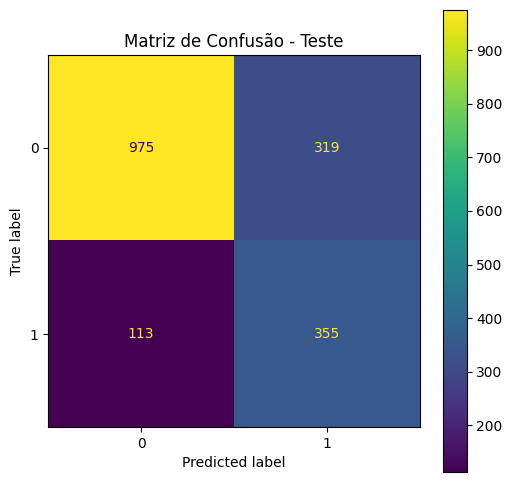

In [30]:
# === 6. Matriz de Confusão ===
fig, ax = plt.subplots(figsize=(6,6))
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, ax=ax)
plt.title("Matriz de Confusão - Teste")
plt.show()

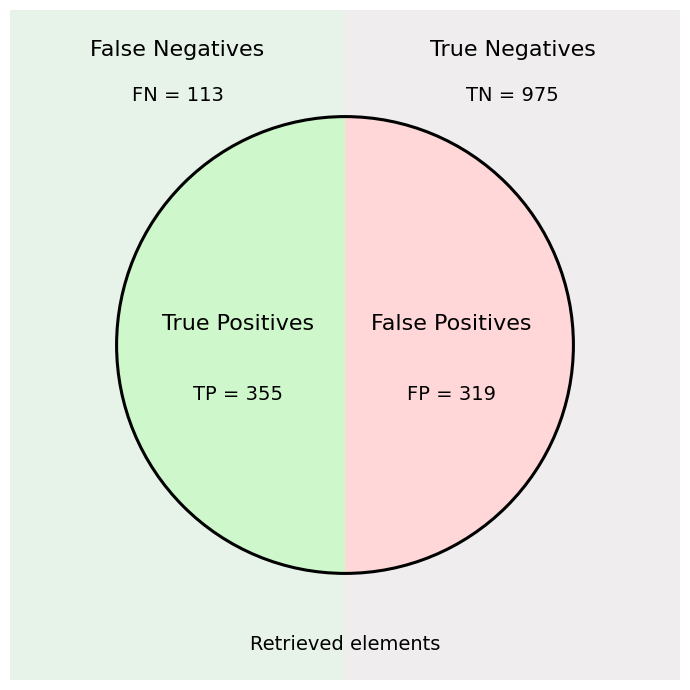

In [31]:
# === 7. Diagrama TN, FP, FN, TP ===
tn, fp, fn, tp = confusion_matrix(y_test, y_test_pred).ravel()

fig, ax = plt.subplots(figsize=(7,7))
ax.set_aspect('equal')
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.axis('off')

# ==========================================
# 1) FUNDOS (fora do círculo)
# ==========================================

# Esquerda (False Negatives)
bg_left  = Rectangle((-1.1, -1.1), 1.1, 2.2, facecolor='#e7f3e8', edgecolor='none', zorder=0)

# Direita (True Negatives)
bg_right = Rectangle((0.0, -1.1), 1.1, 2.2, facecolor='#efeded', edgecolor='none', zorder=0)

ax.add_patch(bg_left)
ax.add_patch(bg_right)

# ==========================================
# 2) METADE INTERNA DO CÍRCULO (TP e FP)
# ==========================================

radius = 0.75
center = (0, 0)

# TP = metade esquerda interna
tp_wedge = Wedge(center, radius, 90, 270, facecolor='#cff7cc', edgecolor='none', zorder=1)
# FP = metade direita interna
fp_wedge = Wedge(center, radius, 270, 90, facecolor='#ffd7d9', edgecolor='none', zorder=1)

ax.add_patch(tp_wedge)
ax.add_patch(fp_wedge)

# Contorno do círculo
ax.add_patch(Circle(center, radius, facecolor='none', edgecolor='black', lw=2.2, zorder=3))

# ==========================================
# 3) TEXTOS
# ==========================================

# ---- Regiões externas ----
# False Negatives (topo esquerdo)
ax.text(-0.55, 0.95, "False Negatives", fontsize=16, ha='center')
ax.text(-0.55, 0.80, f"FN = {fn}", fontsize=14, ha='center')

# True Negatives (topo direito)
ax.text(0.55, 0.95, "True Negatives", fontsize=16, ha='center')
ax.text(0.55, 0.80, f"TN = {tn}", fontsize=14, ha='center')

# ---- Regiões internas ----
ax.text(-0.35, 0.05, "True Positives", fontsize=16, ha='center')
ax.text(-0.35, -0.18, f"TP = {tp}", fontsize=14, ha='center')

ax.text( 0.35, 0.05, "False Positives", fontsize=16, ha='center')
ax.text( 0.35, -0.18, f"FP = {fp}", fontsize=14, ha='center')

# Texto inferior
ax.text(0, -1.0, "Retrieved elements", fontsize=14, ha='center')

plt.tight_layout()
plt.show()

In [32]:
# ==============================================================================
# 8. Teste Kolmogorov-Smirnov (KS) - Correção de Índices
# ==============================================================================

# 1. Converter explicitamente para NumPy para ignorar índices do Pandas
probs = np.array(y_test_proba)
labels = np.array(y_test)

# 2. Dividir probabilidades por classe
probs_0 = np.sort(probs[labels == 0])
probs_1 = np.sort(probs[labels == 1])

# 3. CDFs (acumuladas)
cdf_0 = np.arange(1, len(probs_0) + 1) / len(probs_0)
cdf_1 = np.arange(1, len(probs_1) + 1) / len(probs_1)

# 4. Emparelhamento por grade comum de thresholds
all_probs = np.sort(np.unique(probs))
cdf0_interp = np.interp(all_probs, probs_0, cdf_0)
cdf1_interp = np.interp(all_probs, probs_1, cdf_1)

# 5. KS por diferença máxima
ks_values = np.abs(cdf1_interp - cdf0_interp)
ks_stat = np.max(ks_values)
best_threshold = all_probs[np.argmax(ks_values)]

print("KS Statistic:", ks_stat)
print("Best threshold:", best_threshold)

KS Statistic: 0.5407971324430701
Best threshold: 0.4479372203350067


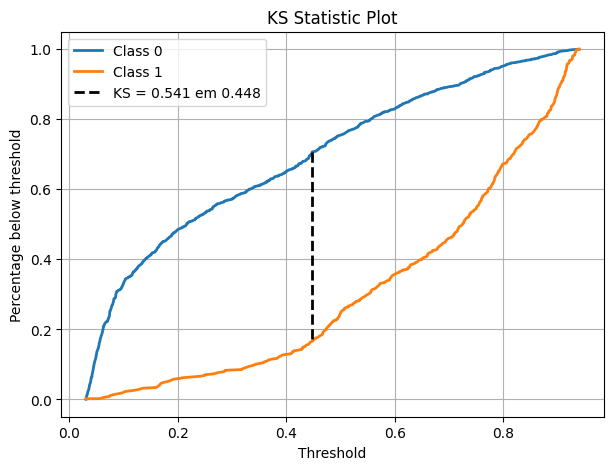

In [33]:
# === 8.5. Gráfico KS ===
plt.figure(figsize=(7, 5))
plt.plot(all_probs, cdf0_interp, label="Class 0", linewidth=2)
plt.plot(all_probs, cdf1_interp, label="Class 1", linewidth=2)

# Linha pontilhada do KS
plt.plot([best_threshold, best_threshold],
         [cdf0_interp[np.argmax(ks_values)], cdf1_interp[np.argmax(ks_values)]],
         'k--', linewidth=2, label=f'KS = {ks_stat:.3f} em {best_threshold:.3f}')

plt.title("KS Statistic Plot")
plt.xlabel("Threshold")
plt.ylabel("Percentage below threshold")

plt.legend()
plt.grid(True)
plt.show()

In [34]:
# === 9. AUROC ===
auc = roc_auc_score(y_test, y_test_proba)
print("AUC (Área sob a ROC):", auc)

AUC (Área sob a ROC): 0.8424434272579558


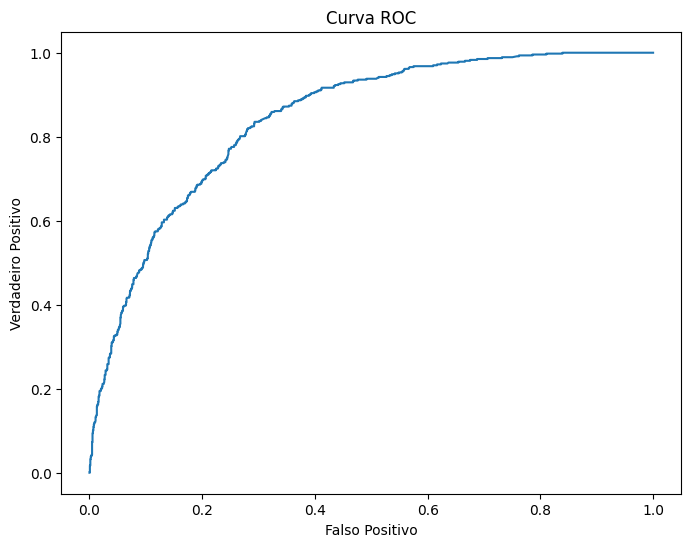

In [35]:
# === 9.5. Curva ROC ===
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr)
plt.title("Curva ROC")
plt.xlabel("Falso Positivo")
plt.ylabel("Verdadeiro Positivo")
plt.show()

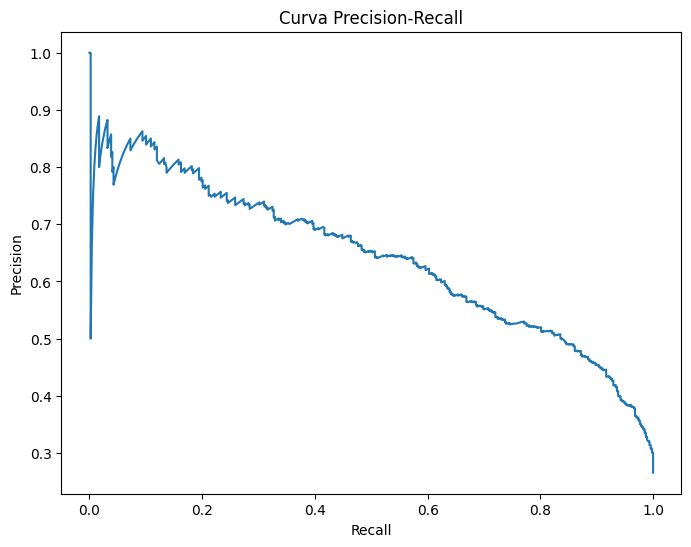

In [36]:
# === 10. Curva Precision-Recall ===
prec, rec, thr = precision_recall_curve(y_test, y_test_proba)
plt.figure(figsize=(8,6))
plt.plot(rec, prec)
plt.title("Curva Precision-Recall")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

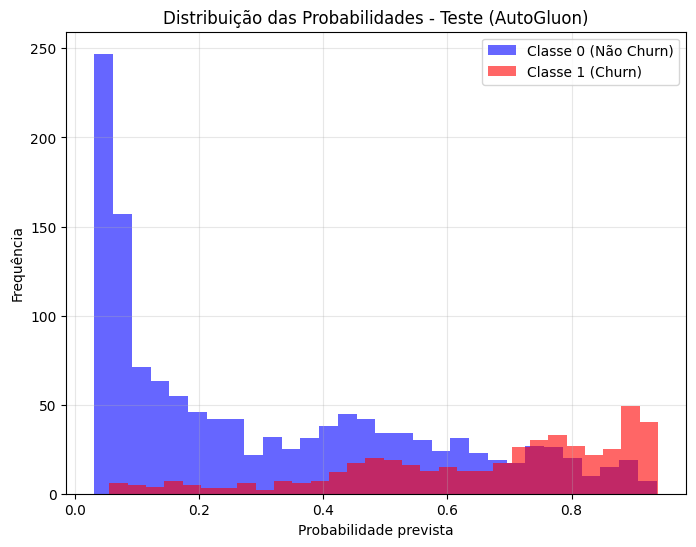

In [37]:
# === 11. Distribuição das probabilidades (Correção de Índices) ===
import numpy as np
import matplotlib.pyplot as plt

# 1. Converter explicitamente para NumPy para ignorar os índices conflitantes
probs = np.array(y_test_proba)
labels = np.array(y_test)

plt.figure(figsize=(8,6))

# 2. Agora o filtro [labels==0] funciona por posição, não por índice
plt.hist(probs[labels==0], bins=30, alpha=0.6, label='Classe 0 (Não Churn)', color='blue')
plt.hist(probs[labels==1], bins=30, alpha=0.6, label='Classe 1 (Churn)', color='red')

plt.title("Distribuição das Probabilidades - Teste (AutoGluon)")
plt.xlabel("Probabilidade prevista")
plt.ylabel("Frequência")
plt.legend()
plt.grid(alpha=0.3)
plt.show()